In [2]:
import pandas as pd
import os

SPLITS_DIR = r"D:\Project\data\splits"
df_train = pd.read_csv(os.path.join(SPLITS_DIR, "train.csv"))

print("Các cột có trong file train.csv của bạn là:")
print(df_train.columns.tolist())

Các cột có trong file train.csv của bạn là:
['image_id', 'specimen_id', 'disease_label', 'file_path', 'width', 'height', 'phash', 'split']


--- BẢNG THỐNG KÊ SỐ LƯỢNG MẪU THEO TẬP VÀ LỚP BỆNH ---
split          Test  Train  Validation
disease_label                         
Fish_1            8      1           8
Fish_10           7      0           7
Fish_11           8      0           8
Fish_12           9      1           1
Fish_13          11      1          11
...             ...    ...         ...
Fish_83          91      1           1
Fish_84          72      2           1
Fish_85          85      4           1
Fish_86          65      1          65
Fish_9            4      0           4

[86 rows x 3 columns]


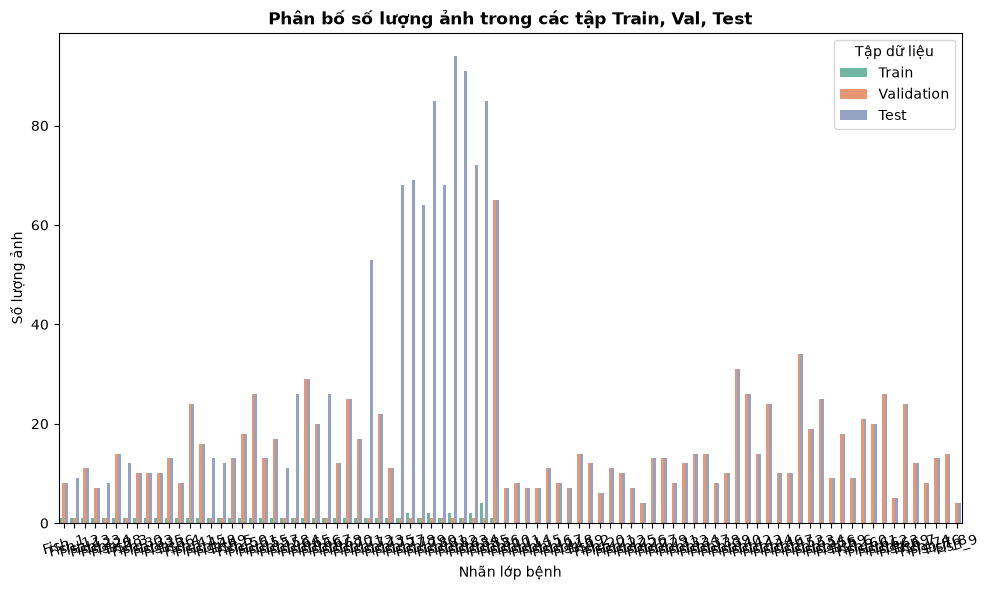


Đã lưu biểu đồ thành công tại: D:\Project\data\splits\week1_data_distribution.png


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Đường dẫn thư mục chứa các file đã chia ở Tuần 1
SPLITS_DIR = r"D:\Project\data\splits"

# 1. Đọc 3 file train, val, test
df_train = pd.read_csv(os.path.join(SPLITS_DIR, "train.csv"))
df_val = pd.read_csv(os.path.join(SPLITS_DIR, "val.csv"))
df_test = pd.read_csv(os.path.join(SPLITS_DIR, "test.csv"))

# Gắn nhãn tập dữ liệu để phân biệt trên biểu đồ
df_train['split'] = 'Train'
df_val['split'] = 'Validation'
df_test['split'] = 'Test'

# Gộp lại thành một bảng dữ liệu chung
df_full = pd.concat([df_train, df_val, df_test], ignore_index=True)

# 2. In ra bảng thống kê số lượng chi tiết (để đưa số liệu vào báo cáo Word)
print("--- BẢNG THỐNG KÊ SỐ LƯỢNG MẪU THEO TẬP VÀ LỚP BỆNH ---")
pivot_table = pd.pivot_table(df_full, index='disease_label', columns='split', values='file_path', aggfunc='count', fill_value=0)
print(pivot_table)

# 3. Vẽ biểu đồ phân bố và lưu lại
plt.figure(figsize=(10, 6))
sns.countplot(data=df_full, x='disease_label', hue='split', palette='Set2')
plt.title('Phân bố số lượng ảnh trong các tập Train, Val, Test', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn lớp bệnh', fontsize=10)
plt.ylabel('Số lượng ảnh', fontsize=10)
plt.xticks(rotation=15)
plt.legend(title='Tập dữ liệu')
plt.tight_layout()

output_path = r"D:\Project\data\splits\week1_data_distribution.png"
plt.savefig(output_path, dpi=300)
plt.show()

print(f"\nĐã lưu biểu đồ thành công tại: {output_path}")

=== BƯỚC 1: Đang quét thư mục và làm sạch dữ liệu (pHash) ===
-> Tổng số file tìm thấy: 2139


100%|██████████| 2139/2139 [06:11<00:00,  5.76it/s]



Đã lưu metadata thành công! Tổng số ảnh hợp lệ: 1939
Phân bố số lượng theo 4 lớp bệnh chính:
disease_label
Healthy Fish                           787
Bacterial Red Diseases                 590
Epizootic Ulcerative Syndrome (EUS)    304
Bacterial Gill Diseases                258
Name: count, dtype: int64

=== BƯỚC 2: Phân chia tập dữ liệu chống rò rỉ (Data Leakage) ===
Đã chia tập xong: Train (53), Val (9), Test (1877)

=== BƯỚC 3: Thống kê bảng Pivot Table và Vẽ biểu đồ EDA ===

--- BẢNG THỐNG KÊ SỐ LƯỢNG MẪU THEO TẬP VÀ LỚP BỆNH ---
split                                Test  Train  Validation
disease_label                                               
Bacterial Gill Diseases               247     10           1
Bacterial Red Diseases                574     14           2
Epizootic Ulcerative Syndrome (EUS)   292     10           2
Healthy Fish                          764     19           4


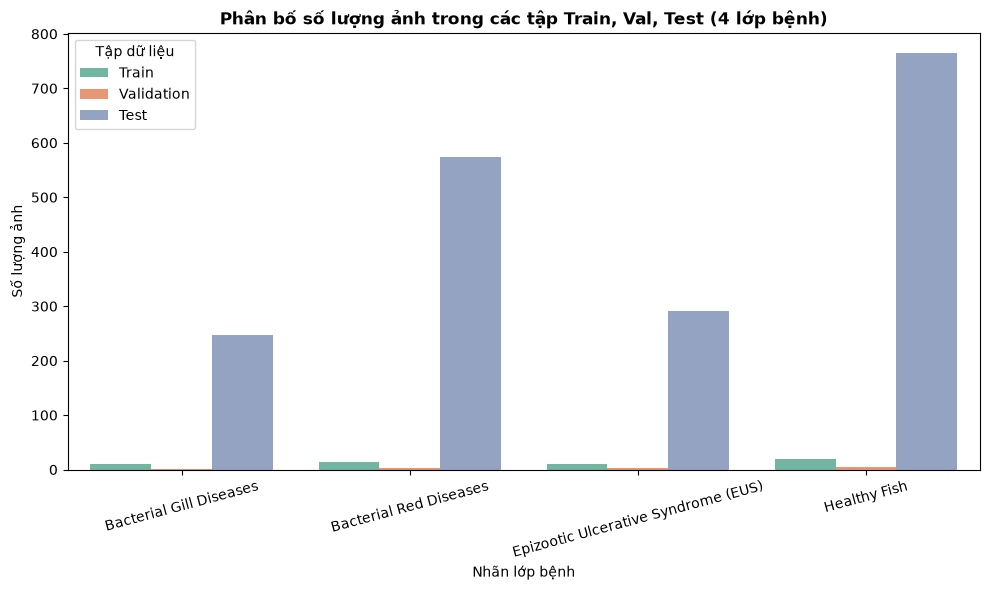


=> HOÀN TẤT TOÀN BỘ TUẦN 1!
Bảng thống kê 4 dòng đã sẵn sàng copy vào Word.
Biểu đồ đã được lưu tự động tại: D:\Project\data\splits\week1_data_distribution.png


In [4]:
import os
from PIL import Image
import imagehash
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# --- BƯỚC 1: QUÉT THƯ MỤC GỐC VÀ TẠO METADATA VỚI 4 LỚP BỆNH CHÍNH ---
RAW_DIR = r"D:\Project\data\raw"  
OUTPUT_CSV = r"D:\Project\data\metadata_v2.csv"
SPLITS_DIR = r"D:\Project\data\splits"

metadata_list = []
hashes = {}

print("=== BƯỚC 1: Đang quét thư mục và làm sạch dữ liệu (pHash) ===")
if not os.path.exists(RAW_DIR):
    print(f"[LỖI] Thư mục {RAW_DIR} không tồn tại!")
else:
    all_files = []
    for root, dirs, files in os.walk(RAW_DIR):
        for file in files:
            all_files.append(os.path.join(root, file))
            
    print(f"-> Tổng số file tìm thấy: {len(all_files)}")

    for file_path in tqdm(all_files):
        if file_path.lower().endswith(('.jpg', '.jpeg', '.png')):
            file = os.path.basename(file_path)
            
            try:
                pil_img = Image.open(file_path)
                pil_img.verify()
                pil_img = Image.open(file_path)
                width, height = pil_img.size
            except Exception:
                continue
            
            try:
                img_hash = str(imagehash.phash(pil_img))
                if img_hash in hashes:
                    continue
                hashes[img_hash] = file_path
            except Exception:
                img_hash = "unknown"

            # Bóc tách tên lớp bệnh chính xác (Thư mục cấp 1 nằm ngay dưới thư mục raw)
            rel_path = os.path.relpath(file_path, RAW_DIR)
            parts = rel_path.split(os.sep)
            disease_label = parts[0] if len(parts) >= 2 else "Unknown"
            
            filename_no_ext = os.path.splitext(file)[0]
            specimen_id = filename_no_ext.split('_')[0] if '_' in filename_no_ext else "unknown_specimen"

            metadata_list.append({
                "image_id": file,
                "specimen_id": specimen_id,
                "disease_label": disease_label,
                "file_path": file_path,
                "width": width,
                "height": height,
                "phash": img_hash
            })

if len(metadata_list) > 0:
    df_meta = pd.DataFrame(metadata_list)
    os.makedirs(os.path.dirname(OUTPUT_CSV), exist_ok=True)
    
    with open(OUTPUT_CSV, "w", encoding="utf-8") as f:
        f.write(df_meta.to_csv(index=False))
        
    print(f"\nĐã lưu metadata thành công! Tổng số ảnh hợp lệ: {len(df_meta)}")
    print("Phân bố số lượng theo 4 lớp bệnh chính:")
    print(df_meta['disease_label'].value_counts())

    # --- BƯỚC 2: CHIA TẬP TRAIN / VAL / TEST THEO SPECIMEN_ID ---
    print("\n=== BƯỚC 2: Phân chia tập dữ liệu chống rò rỉ (Data Leakage) ===")
    train_list, val_list, test_list = [], [], []
    
    for disease, group in df_meta.groupby('disease_label'):
        unique_specimens = group['specimen_id'].unique()
        n_specimens = len(unique_specimens)
        
        n_test = max(1, int(n_specimens * 0.15))
        n_val = max(1, int(n_specimens * 0.15))
        n_train = n_specimens - n_test - n_val
        if n_train < 1: n_train = 1
            
        test_specimens = unique_specimens[:n_test]
        val_specimens = unique_specimens[n_test:n_test + n_val]
        train_specimens = unique_specimens[n_test + n_val:]
        if len(train_specimens) == 0:
            train_specimens = val_specimens
            val_specimens = test_specimens
            
        train_list.append(group[group['specimen_id'].isin(train_specimens)])
        val_list.append(group[group['specimen_id'].isin(val_specimens)])
        test_list.append(group[group['specimen_id'].isin(test_specimens)])

    df_train = pd.concat(train_list, ignore_index=True)
    df_val = pd.concat(val_list, ignore_index=True)
    df_test = pd.concat(test_list, ignore_index=True)
    
    df_train['split'] = 'Train'
    df_val['split'] = 'Validation'
    df_test['split'] = 'Test'
    
    os.makedirs(SPLITS_DIR, exist_ok=True)
    df_train.to_csv(os.path.join(SPLITS_DIR, "train.csv"), index=False)
    df_val.to_csv(os.path.join(SPLITS_DIR, "val.csv"), index=False)
    df_test.to_csv(os.path.join(SPLITS_DIR, "test.csv"), index=False)
    
    print(f"Đã chia tập xong: Train ({len(df_train)}), Val ({len(df_val)}), Test ({len(df_test)})")

    # --- BƯỚC 3: IN BẢNG PIVOT TABLE VÀ VẼ BIỂU ĐỒ TRỰC QUAN ---
    print("\n=== BƯỚC 3: Thống kê bảng Pivot Table và Vẽ biểu đồ EDA ===")
    df_full = pd.concat([df_train, df_val, df_test], ignore_index=True)
    
    print("\n--- BẢNG THỐNG KÊ SỐ LƯỢNG MẪU THEO TẬP VÀ LỚP BỆNH ---")
    pivot_table = pd.pivot_table(df_full, index='disease_label', columns='split', values='file_path', aggfunc='count', fill_value=0)
    print(pivot_table)

    plt.figure(figsize=(10, 6))
    sns.countplot(data=df_full, x='disease_label', hue='split', palette='Set2')
    plt.title('Phân bố số lượng ảnh trong các tập Train, Val, Test (4 lớp bệnh)', fontsize=12, fontweight='bold')
    plt.xlabel('Nhãn lớp bệnh', fontsize=10)
    plt.ylabel('Số lượng ảnh', fontsize=10)
    plt.xticks(rotation=15)
    plt.legend(title='Tập dữ liệu')
    plt.tight_layout()

    output_path = os.path.join(SPLITS_DIR, "week1_data_distribution.png")
    plt.savefig(output_path, dpi=300)
    plt.show()

    print(f"\n=> HOÀN TẤT TOÀN BỘ TUẦN 1!")
    print(f"Bảng thống kê 4 dòng đã sẵn sàng copy vào Word.")
    print(f"Biểu đồ đã được lưu tự động tại: {output_path}")